**Regresión Lineal Simple y Múltiple - Histórico de Ventas CLV**

Se trabaja sobre `historico_ventas_clv_listo.csv`, el dataset que salió del pre-procesamiento: sin nulos, sin outliers (IQR), variables numéricas estandarizadas y categóricas en columnas 0/1.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Cargar archivo csv con el dataset ya pre-procesado
df= pd.read_csv("historico_ventas_clv_listo.csv")
df.head(5)

,precio_unitario,total_unidades,total_neto,mes,dia_semana,dia_mes,folio_abreviado_B00,folio_abreviado_CDF,folio_abreviado_CP0,folio_abreviado_XDF,...,vendedor_LUISMAC,vendedor_MARIFER,vendedor_NAYELI,vendedor_NAYELI_BO_RODRIGO,vendedor_PIETRO,vendedor_RENE,vendedor_RENE_BO_YAMEL,vendedor_SERGIO_SANCHEZ,vendedor_SERV_TEC,vendedor_infrequent_sklearn
0,1.041704,-0.501647,0.210018,1.733802,0.724458,-0.161285,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
#Revisamos el tamaño del dataset y las variables numéricas continuas disponibles
print(df.shape)
Vars_Numericas= ['precio_unitario', 'total_unidades', 'total_neto', 'mes', 'dia_semana', 'dia_mes']
df[Vars_Numericas].describe()

(21632, 67)


,precio_unitario,total_unidades,total_neto,mes,dia_semana,dia_mes
count,2.163200e+04,2.163200e+04,2.163200e+04,2.163200e+04,2.163200e+04,2.163200e+04
mean,9.197114e-18,3.613152e-17,1.970810e-16,-8.408790e-17,-1.734313e-16,1.156209e-16
std,1.000023e+00,1.000023e+00,1.000023e+00,1.000023e+00,1.000023e+00,1.000023e+00
min,-1.138709e+00,-5.016471e-01,-1.000158e+00,-1.602797e+00,-1.412659e+00,-1.750306e+00
25%,-8.518134e-01,-5.016471e-01,-8.154479e-01,-8.613310e-01,-7.002866e-01,-8.422944e-01
50%,-2.923677e-01,-5.016471e-01,-2.763612e-01,-1.198645e-01,1.208583e-02,-4.778376e-02
75%,8.580822e-01,-5.016471e-01,2.896379e-01,9.923353e-01,7.244583e-01,8.602283e-01
max,3.767190e+00,2.944409e+00,3.681310e+00,1.733802e+00,2.861576e+00,1.654739e+00


**Análisis de correlación**

In [4]:
#Encontramos todas las correlaciones entre las variables
Corr_Factors=df.corr()
Corr_Factors[Vars_Numericas].loc[Vars_Numericas]

,precio_unitario,total_unidades,total_neto,mes,dia_semana,dia_mes
precio_unitario,1.000000,0.087244,0.596729,0.012000,0.004192,-0.052307
total_unidades,0.087244,1.000000,0.325540,0.008231,-0.008860,-0.023519
total_neto,0.596729,0.325540,1.000000,0.007027,0.014383,-0.019422
mes,0.012000,0.008231,0.007027,1.000000,-0.076346,-0.145164
dia_semana,0.004192,-0.008860,0.014383,-0.076346,1.000000,0.047486
dia_mes,-0.052307,-0.023519,-0.019422,-0.145164,0.047486,1.000000


In [5]:
#Encontramos el valor absoluto de todas las correlaciones entre las variables
Corr_Factors1= abs(Corr_Factors)

#Ordenamos las correlaciones contra total_neto para ver cual variable explica mejor el monto de la venta
Corr_Factors1['total_neto'].drop('total_neto').sort_values(ascending=False).head(10)

precio_unitario            0.596729
marca_VITA                 0.433320
total_unidades             0.325540
marca_AIDITE               0.270821
folio_abreviado_CP0        0.205478
estado_CIUDAD_DE_MEXICO    0.171214
estado_JALISCO             0.140510
vendedor_JAVIERCAD         0.139977
folio_abreviado_B00        0.137265
folio_abreviado_XDF        0.134098
Name: total_neto, dtype: float64

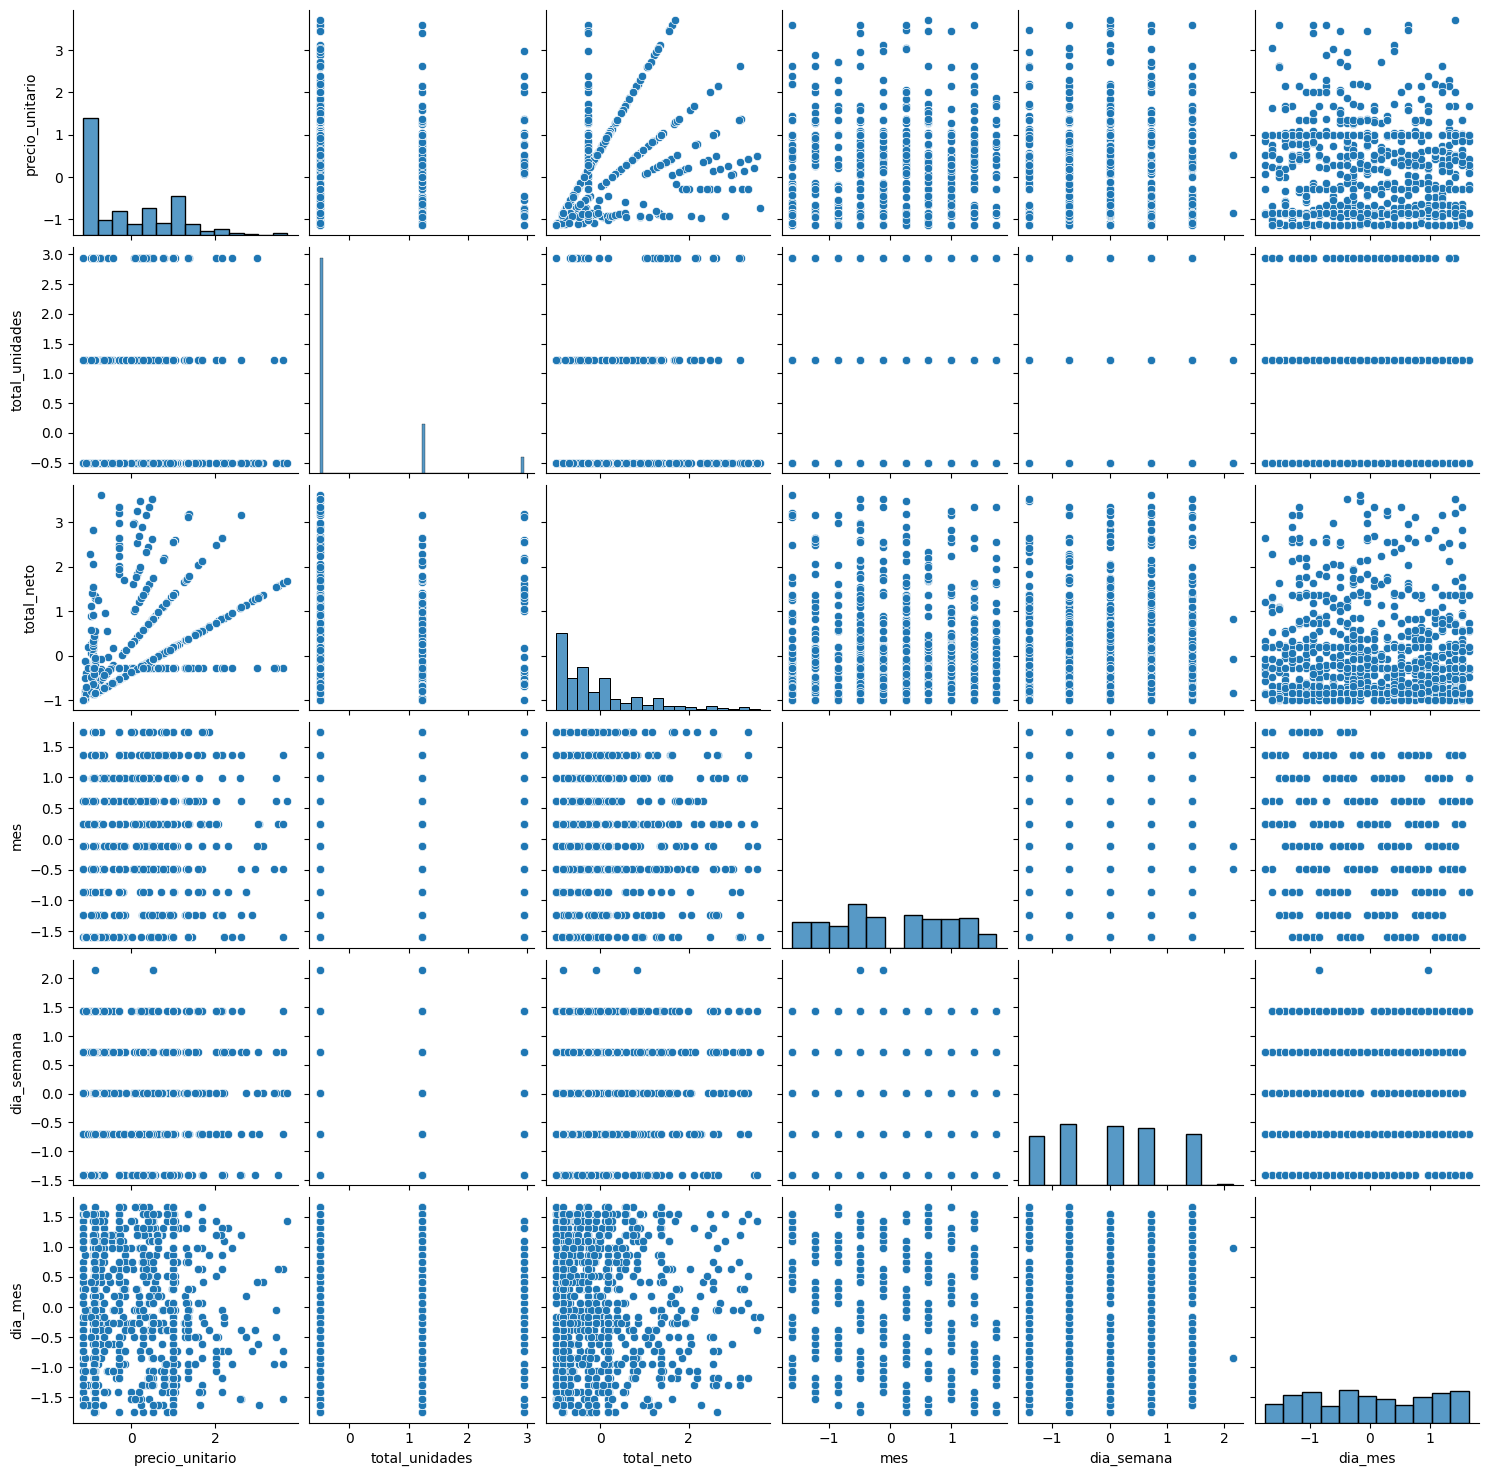

In [6]:
#Graficamos todas las dispersiones entre las variables numéricas
#Se usa una muestra de 1000 filas porque el dataset tiene 21,632 registros
sns.pairplot(df[Vars_Numericas].sample(1000, random_state=42))

<Axes: >

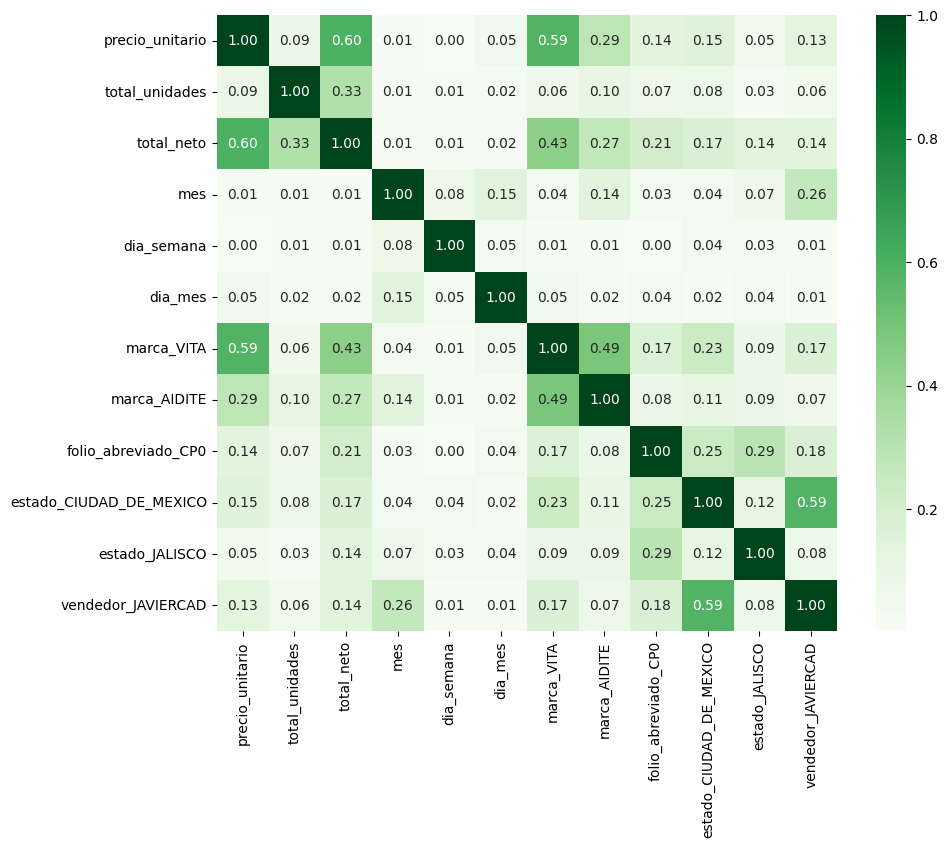

In [7]:
#Seleccionamos las variables numéricas más las 6 categóricas con mayor correlación para que el mapa de calor sea legible
Top_Categoricas= Corr_Factors1['total_neto'].drop(Vars_Numericas).sort_values(ascending=False).head(6).index.tolist()
Vars_Mapa= Vars_Numericas + Top_Categoricas

#Graficamos el mapa de calor de los coeficientes de correlación
plt.figure(figsize=(10,8))
Heat_Map= sns.heatmap(Corr_Factors1.loc[Vars_Mapa, Vars_Mapa], cmap = 'Greens', annot=True, fmt=".2f")
Heat_Map

La correlación más alta de la base entre dos variables de negocio es **total_neto vs precio_unitario (0.597)**.

Existen correlaciones mayores entre columnas dummy (por ejemplo `vendedor_SERV_TEC` con `folio_abreviado_infrequent_sklearn`, 0.82), pero son estructurales: un vendedor atiende siempre el mismo canal o la misma zona, así que la dummy de uno predice la del otro. No sirven para un modelo de regresión porque no explican una cantidad, solo reflejan como está organizada la operación.

Por eso el modelo simple se ajusta sobre `precio_unitario` para explicar `total_neto`, que es la variable cuantitativa de mayor valor para CLV: el monto facturado por línea de venta.

<Axes: xlabel='precio_unitario', ylabel='total_neto'>

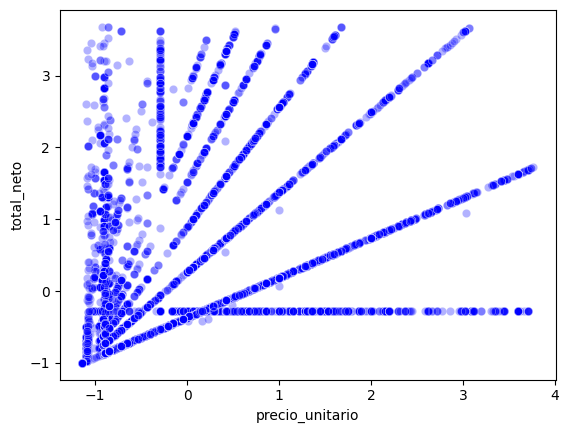

In [8]:
#Imprimimos el scatter plot entre la variable dependiente (total_neto) e independiente (precio_unitario)
#para observar el comportamiento en su dispersión
sns.scatterplot(x='precio_unitario', y='total_neto', color="blue", data=df, alpha=0.3)

**Regresión Lineal Simple**

In [9]:
#Declaramos las variables dependientes e independientes para la regresión lineal
Vars_Indep= df[['precio_unitario']]
Var_Dep= df['total_neto']

In [10]:
#Se define model como la función de regresión lineal
from sklearn.linear_model import LinearRegression
model= LinearRegression()

In [11]:
#Ajustamos el modelo con las variables antes declaradas
model.fit(X=Vars_Indep, y=Var_Dep)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [12]:
#Verificamos los coeficientes obtenidos para el modelo ajustado
model.__dict__

{'fit_intercept': True,
 'copy_X': True,
 'tol': 1e-06,
 'n_jobs': None,
 'positive': False,
 'feature_names_in_': array(['precio_unitario'], dtype=object),
 'n_features_in_': 1,
 'coef_': array([0.59672925]),
 'rank_': 1,
 'singular_': array([147.07821049]),
 'intercept_': np.float64(1.91592823472752e-16)}

**Modelo matemático: y= 0.59672925x + 0.0000**

Como las variables vienen estandarizadas del pre-procesamiento, la pendiente coincide con el coeficiente de correlación de Pearson (0.5967) y la ordenada al origen es cero. La lectura es directa: por cada desviación estándar que sube el precio unitario, el total neto de la línea sube 0.60 desviaciones estándar.

In [13]:
#Evaluamos la eficiencia del modelo obtenido por medio del coeficiente R Determinación
model.score(Vars_Indep,Var_Dep)

0.3560857962049242

In [14]:
#Predecimos los valores de total neto a partir de la variable "precio_unitario"
y_pred= model.predict(X=df[['precio_unitario']])
y_pred

array([ 0.62161508, -0.17446436, -0.17446436, ..., -0.50829581,
       -0.50829581, -0.50830573], shape=(21632,))

In [15]:
#Insertamos la columna de predicciones en el DataFrame
df.insert(0, 'Predicciones', y_pred)
df.head()

,Predicciones,precio_unitario,total_unidades,total_neto,mes,dia_semana,dia_mes,folio_abreviado_B00,folio_abreviado_CDF,folio_abreviado_CP0,...,vendedor_LUISMAC,vendedor_MARIFER,vendedor_NAYELI,vendedor_NAYELI_BO_RODRIGO,vendedor_PIETRO,vendedor_RENE,vendedor_RENE_BO_YAMEL,vendedor_SERGIO_SANCHEZ,vendedor_SERV_TEC,vendedor_infrequent_sklearn
0,0.621615,1.041704,-0.501647,0.210018,1.733802,0.724458,-0.161285,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,-0.174464,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,-0.174464,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,-0.174464,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,-0.174464,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,...,0,0,0,0,0,0,0,0,0,0


<Axes: xlabel='precio_unitario', ylabel='total_neto'>

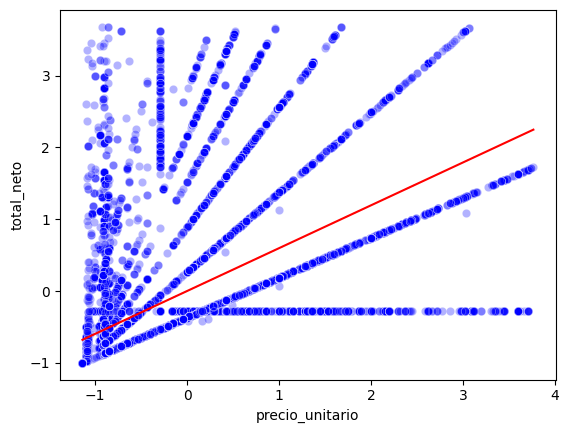

In [16]:
#Visualizamos la gráfica comparativa entre el total neto real y el predecido
sns.scatterplot(x='precio_unitario', y='total_neto', color="blue", data=df, alpha=0.3)
sns.lineplot(x='precio_unitario', y='Predicciones', color="red", data=df)

In [17]:
#Corroboramos cual es el coeficiente de Determinación de nuestro modelo
coef_Deter=model.score(X=Vars_Indep, y=Var_Dep)
coef_Deter

0.3560857962049242

In [18]:
#Corroboramos cual es el coeficiente de Correlación de nuestro modelo
coef_Correl=np.sqrt(coef_Deter)
coef_Correl

np.float64(0.5967292486588237)

El modelo simple explica el 35.6% de la variación del total neto. El precio unitario solo no alcanza porque una línea de venta también depende de cuantas piezas se llevaron y de que producto se trata.

**Regresión Lineal Múltiple**

In [19]:
#Tomamos las variables con mayor correlación contra total_neto como candidatas al modelo múltiple
Candidatas= Corr_Factors1['total_neto'].drop('total_neto').sort_values(ascending=False)
Candidatas.head(10)

precio_unitario            0.596729
marca_VITA                 0.433320
total_unidades             0.325540
marca_AIDITE               0.270821
folio_abreviado_CP0        0.205478
estado_CIUDAD_DE_MEXICO    0.171214
estado_JALISCO             0.140510
vendedor_JAVIERCAD         0.139977
folio_abreviado_B00        0.137265
folio_abreviado_XDF        0.134098
Name: total_neto, dtype: float64

In [20]:
#Comparamos el coeficiente de determinación conforme se agregan variables para ubicar el punto donde deja de mejorar
Comparativo= []
for k in [1, 2, 4, 6, 8, 10, 20, len(Candidatas)]:
    Cols= list(Candidatas.head(k).index)
    R2= LinearRegression().fit(df[Cols], Var_Dep).score(df[Cols], Var_Dep)
    Comparativo.append({'variables': k, 'coef_Determinacion': round(R2, 4)})

pd.DataFrame(Comparativo)

,variables,coef_Determinacion
0,1,0.3561
1,2,0.3667
2,4,0.4432
3,6,0.4536
4,8,0.4581
5,10,0.4591
6,20,0.4663
7,66,0.4806


A partir de 6 variables la ganancia es marginal: pasar de 6 a las 66 disponibles sube el coeficiente de determinación de 0.4536 a 0.4806, menos de 3 puntos a cambio de 60 variables extra y de meter colinealidad entre las dummies de vendedor y estado. El mejor modelo es el de 6 variables.

In [21]:
#Declaramos las variables dependientes e independientes para la regresión lineal múltiple
Vars_Indep_Mult= df[['precio_unitario', 'total_unidades', 'marca_VITA', 'marca_AIDITE',
                     'folio_abreviado_CP0', 'estado_CIUDAD_DE_MEXICO']]
Var_Dep= df['total_neto']

In [22]:
#Ajustamos el modelo múltiple
model_Mult= LinearRegression()
model_Mult.fit(X=Vars_Indep_Mult, y=Var_Dep)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [23]:
#Verificamos los coeficientes obtenidos para el modelo ajustado
model_Mult.__dict__

{'fit_intercept': True,
 'copy_X': True,
 'tol': 1e-06,
 'n_jobs': None,
 'positive': False,
 'feature_names_in_': array(['precio_unitario', 'total_unidades', 'marca_VITA', 'marca_AIDITE',
        'folio_abreviado_CP0', 'estado_CIUDAD_DE_MEXICO'], dtype=object),
 'n_features_in_': 6,
 'coef_': array([ 0.49561503,  0.26293662, -0.16020165,  0.12041923,  0.23355449,
        -0.06392744]),
 'rank_': 6,
 'singular_': array([160.38810415, 143.03600521,  70.05469835,  62.57160074,
         51.70214694,  44.67945219]),
 'intercept_': np.float64(-0.0013471172979388705)}

**Modelo matemático: y= 0.49561503x1 + 0.26293662x2 - 0.16020165x3 + 0.12041923x4 + 0.23355449x5 - 0.06392744x6 - 0.0013471**

donde x1= precio_unitario, x2= total_unidades, x3= marca_VITA, x4= marca_AIDITE, x5= folio_abreviado_CP0, x6= estado_CIUDAD_DE_MEXICO

In [24]:
#Corroboramos el coeficiente de Determinación y de Correlación del modelo múltiple
coef_Deter_Mult=model_Mult.score(X=Vars_Indep_Mult, y=Var_Dep)
coef_Correl_Mult=np.sqrt(coef_Deter_Mult)
print('Coeficiente de Determinación:', coef_Deter_Mult)
print('Coeficiente de Correlación:', coef_Correl_Mult)

Coeficiente de Determinación: 0.45363994882317304
Coeficiente de Correlación: 0.673527986666607


In [25]:
#Predecimos los valores de total neto con el modelo múltiple
y_pred_mult= model_Mult.predict(X=Vars_Indep_Mult)
df['Predicciones_Mult']= y_pred_mult

<Axes: xlabel='precio_unitario', ylabel='total_neto'>

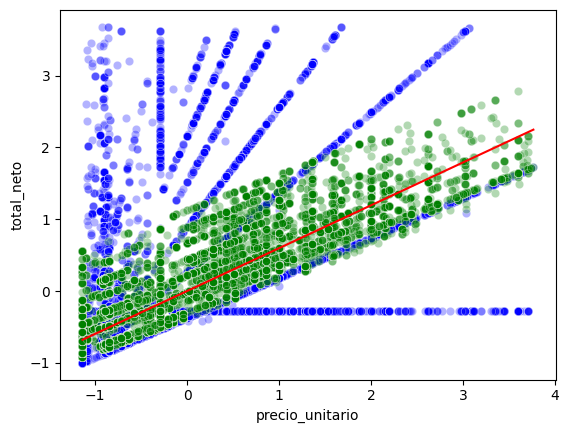

In [26]:
#Visualizamos la gráfica comparativa entre el total neto real y el predecido por los dos modelos
sns.scatterplot(x='precio_unitario', y='total_neto', color="blue", data=df, alpha=0.3)
sns.scatterplot(x='precio_unitario', y='Predicciones_Mult', color="green", data=df, alpha=0.3)
sns.lineplot(x='precio_unitario', y='Predicciones', color="red", data=df)

**Comparación de coeficientes: modelo simple contra modelo múltiple**

In [27]:
#Comparamos el coeficiente de precio_unitario en ambos modelos
Comparacion= pd.DataFrame({
    'variable': Vars_Indep_Mult.columns,
    'coef_simple': [model.coef_[0]] + [np.nan]*5,
    'coef_multiple': model_Mult.coef_,
})
Comparacion.loc[len(Comparacion)]= ['intercepto', model.intercept_, model_Mult.intercept_]
Comparacion.round(4)

,variable,coef_simple,coef_multiple
0,precio_unitario,0.5967,0.4956
1,total_unidades,NaN,0.2629
2,marca_VITA,NaN,-0.1602
3,marca_AIDITE,NaN,0.1204
4,folio_abreviado_CP0,NaN,0.2336
5,estado_CIUDAD_DE_MEXICO,NaN,-0.0639
6,intercepto,0.0000,-0.0013


In [28]:
#Comparamos la capacidad explicativa de los dos modelos
pd.DataFrame({
    'modelo': ['Simple', 'Múltiple'],
    'variables': [1, 6],
    'coef_Determinacion': [coef_Deter, coef_Deter_Mult],
    'coef_Correlacion': [coef_Correl, coef_Correl_Mult],
}).round(4)

,modelo,variables,coef_Determinacion,coef_Correlacion
0,Simple,1,0.3561,0.5967
1,Múltiple,6,0.4536,0.6735


**Lectura de la comparación**

El coeficiente de `precio_unitario` baja de 0.5967 en el modelo simple a 0.4956 en el múltiple, una caída de 17%. En el modelo simple ese coeficiente venía inflado porque cargaba con el efecto de las variables que faltaban: al no incluir `total_unidades`, el precio estaba absorbiendo parte del volumen vendido. Cuando las unidades entran al modelo con su propio coeficiente (0.2629), el precio queda con el efecto que realmente le corresponde.

El resto de los coeficientes agrega contexto comercial: una venta de AIDITE suma 0.12 desviaciones estándar al monto contra la marca de referencia, mientras que VITA resta 0.16 (es un consumible de ticket bajo). El canal CP0 es el de mayor monto por línea (+0.23) y la Ciudad de México queda ligeramente por debajo del promedio nacional (-0.06).

El coeficiente de determinación sube de 0.3561 a 0.4536 y el de correlación de 0.5967 a 0.6735. El modelo múltiple explica 10 puntos porcentuales más de la variación del total neto.

El 55% que queda sin explicar viene de que el total neto es un producto (precio por unidades) y no una suma, por lo que una regresión lineal no lo puede reproducir exacto, y de que el recorte de outliers por IQR aplanó las ventas grandes.